In [41]:
from data_loader import load_dataset_cleaned
import matplotlib.pyplot as plt
import seaborn as sns

df = load_dataset_cleaned()
eda = df.copy()
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Study of Numeric Distributions

In [42]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
eda[numerical_columns].describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,48813.000000,4.881300e+04,48813.000000,48813.000000,48813.000000,48813.000000
mean,38.647348,1.896679e+05,10.078688,1079.708705,87.554299,40.425051
std,13.709005,1.056062e+05,2.570257,7454.185982,403.118605,12.390954
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175550e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781400e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376200e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


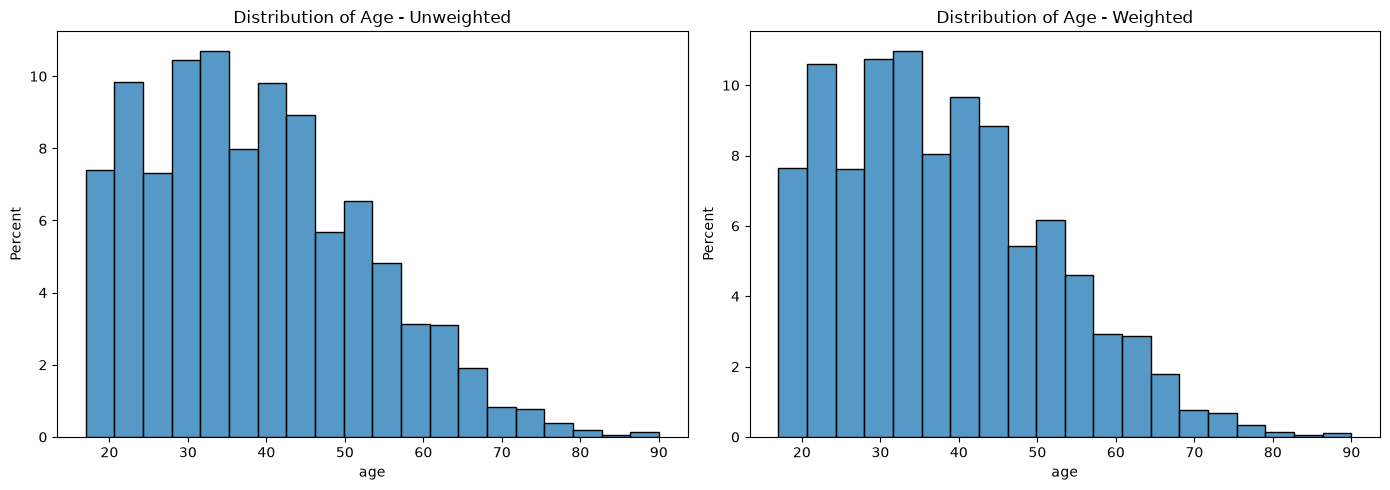

In [43]:
fig, axes = plt.subplots(1,2, figsize=(14,5))

sns.histplot(data=eda, x='age', bins=20, ax=axes[0],stat='percent')

axes[0].set_title('Distribution of Age - Unweighted')

sns.histplot(data=eda, x='age', bins=20, ax=axes[1], stat='percent', weights='fnlwgt')
axes[1].set_title('Distribution of Age - Weighted')

plt.tight_layout()
plt.show()

The age distributions in the dataset is skewed right, indicating an abundance of records with age less than 45 years old.

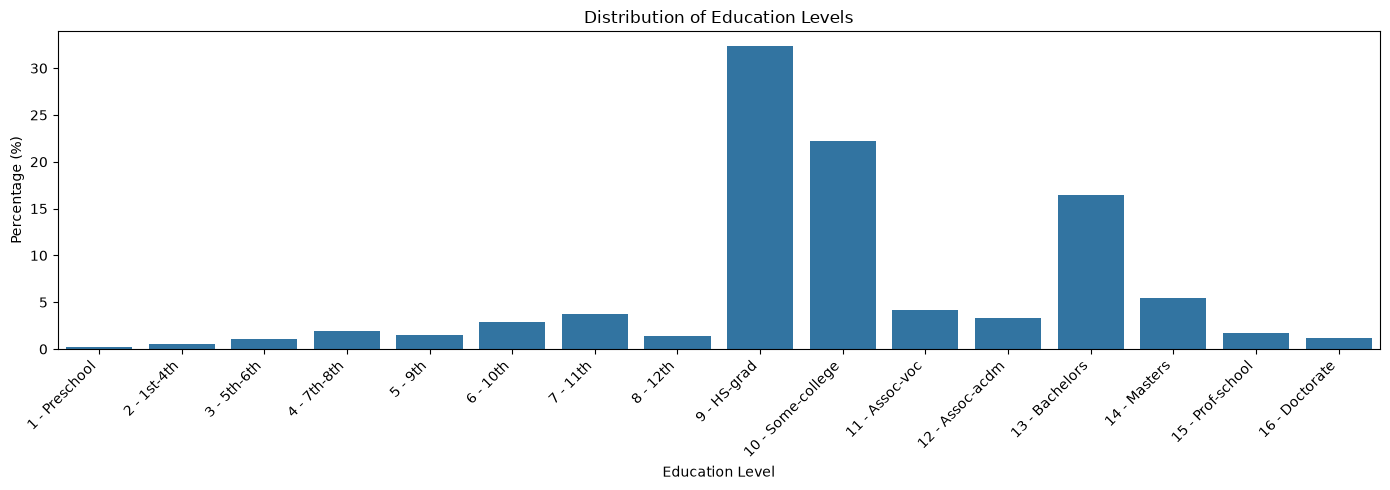

In [44]:
fig, axes = plt.subplots(figsize=(14,5))

education_map = (eda[["education_num","education"]].drop_duplicates().sort_values("education_num"))

education_pct = eda["education_num"].value_counts(normalize=True).sort_index() * 100

sns.barplot(x=education_pct.index, y=education_pct.values, ax=axes)

labels = [f"{row.education_num} - {row.education}" for row in education_map.itertuples()]

axes.set_xticks(range(len(labels)))
axes.set_xticklabels(labels, rotation=45, ha='right')
axes.set_xlabel("Education Level")
axes.set_ylabel("Percentage (%)")
axes.set_title("Distribution of Education Levels")

plt.tight_layout()
plt.show()

The distribution of education is concentrated in 9 and 10 grade.

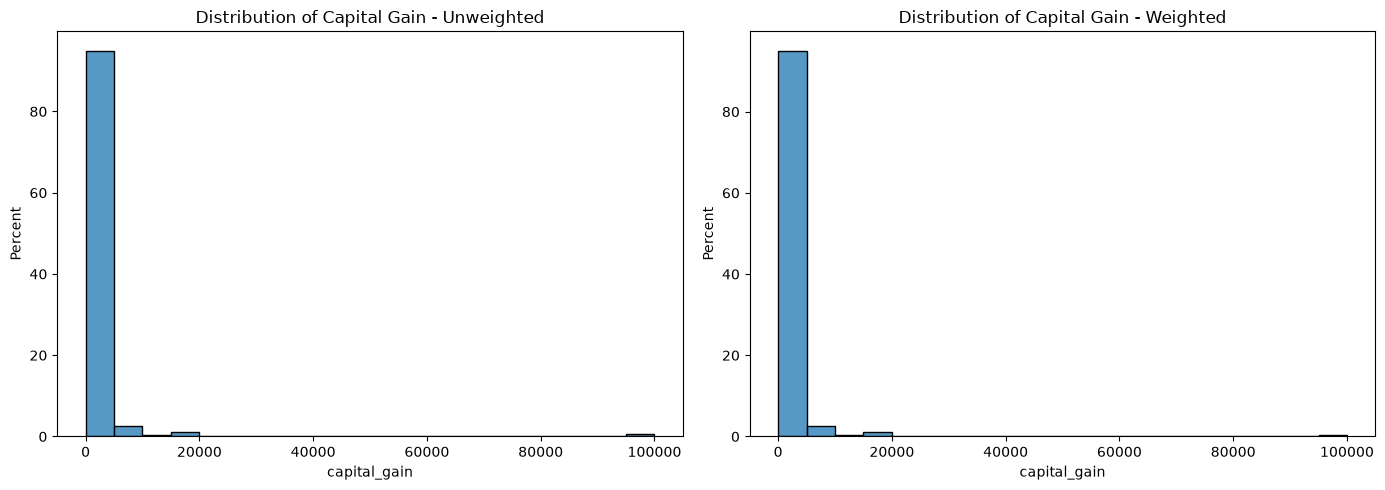

In [48]:
fig, axes = plt.subplots(1,2, figsize=(14,5))

sns.histplot(data=eda, x='capital_gain', bins=20, ax=axes[0],stat='percent')

axes[0].set_title('Distribution of Capital Gain - Unweighted')
    
sns.histplot(data=eda, x='capital_gain', bins=20, ax=axes[1], stat='percent', weights='fnlwgt')
axes[1].set_title('Distribution of Capital Gain - Weighted')

plt.tight_layout()
plt.show()

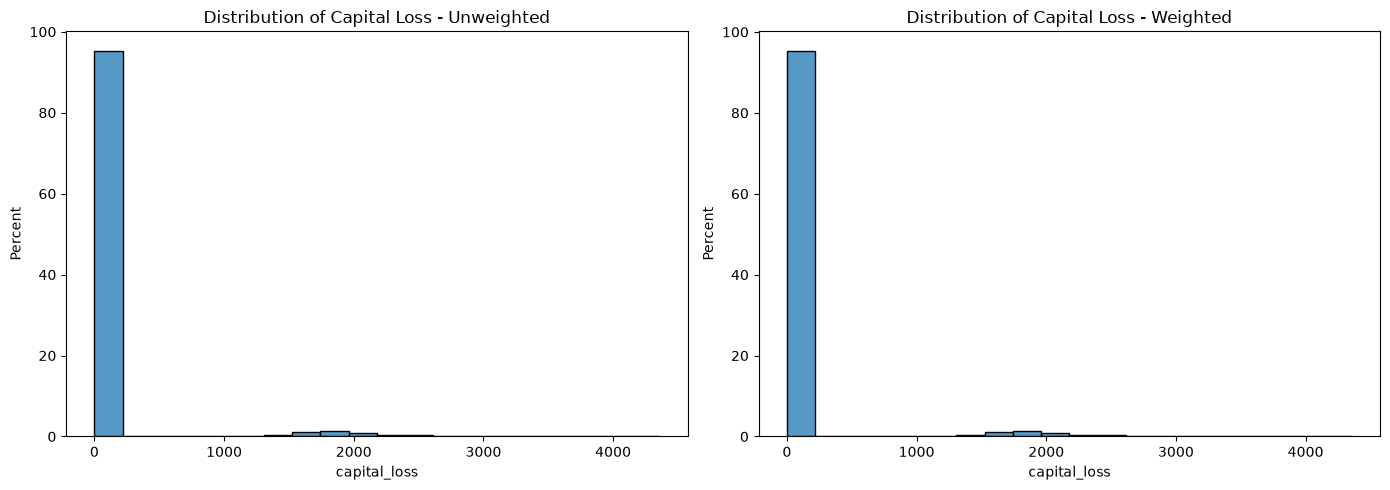

In [50]:
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.histplot(data=eda, x='capital_loss', bins=20, ax=axes[0],stat='percent')

axes[0].set_title('Distribution of Capital Loss - Unweighted')
    
sns.histplot(data=eda, x='capital_loss', bins=20, ax=axes[1], stat='percent', weights='fnlwgt')
axes[1].set_title('Distribution of Capital Loss - Weighted')

plt.tight_layout()
plt.show()

From what transpired in the visualization of capital gain and capital loss >95% of people represented in the dataset does not invest in capital.

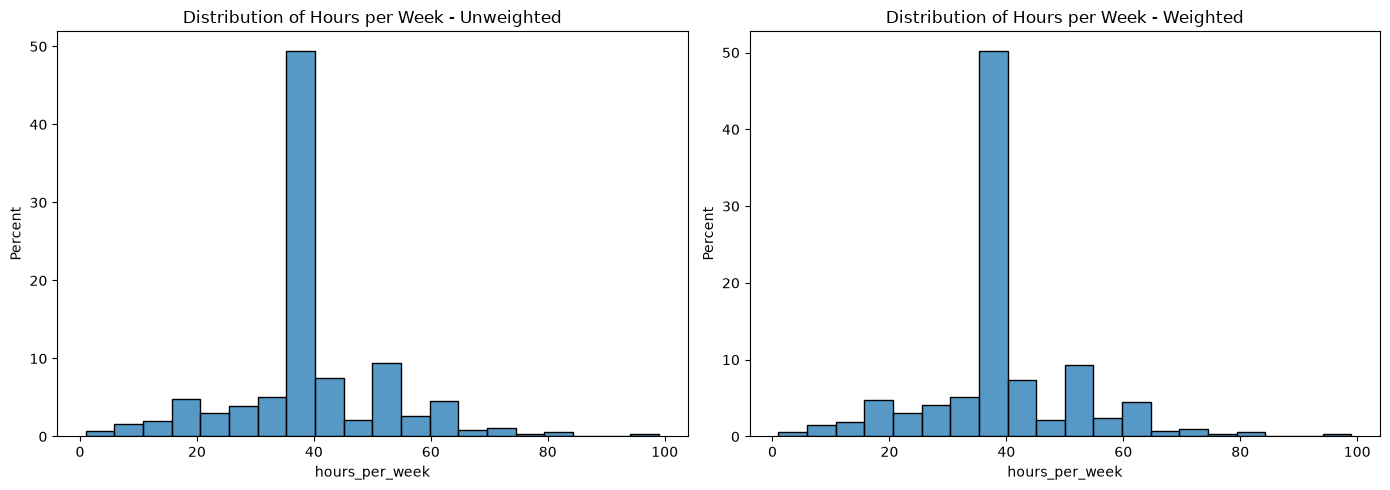

In [51]:
fig, axes = plt.subplots(1,2, figsize=(14,5))
sns.histplot(data=eda, x='hours_per_week', bins=20, ax=axes[0],stat='percent')

axes[0].set_title('Distribution of Hours per Week - Unweighted')
    
sns.histplot(data=eda, x='hours_per_week', bins=20, ax=axes[1], stat='percent', weights='fnlwgt')
axes[1].set_title('Distribution of Hours per Week - Weighted')

plt.tight_layout()
plt.show()

The majority of people represented (48%) works around 40 hours per week, 99 hours per week seems to be an outlier.

## Study of categorical distributions

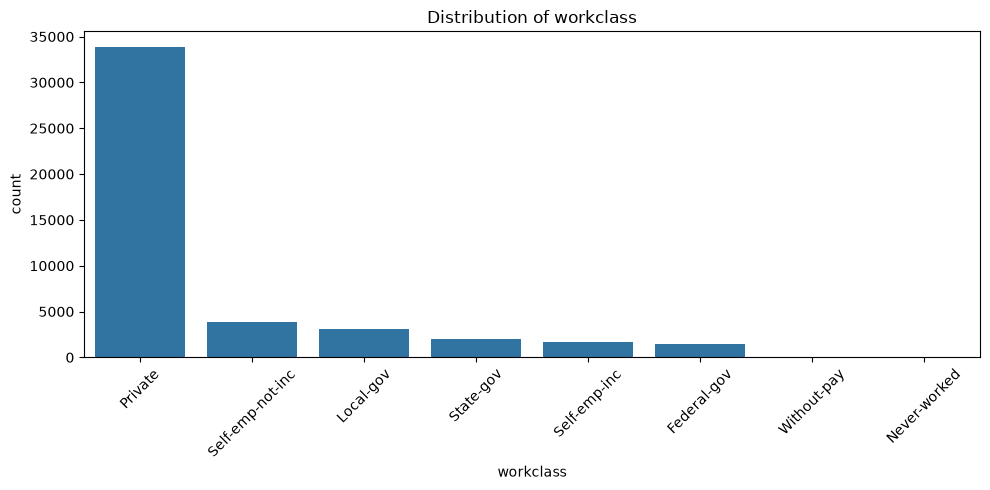

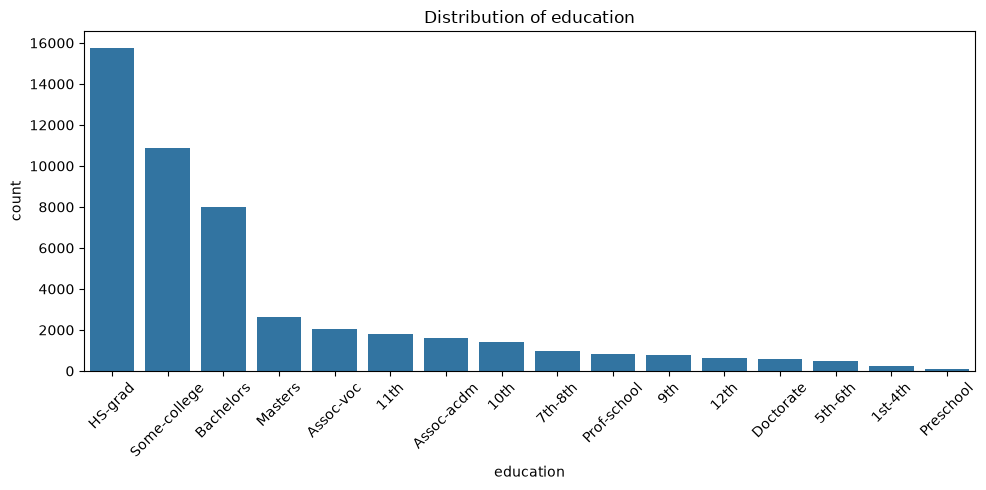

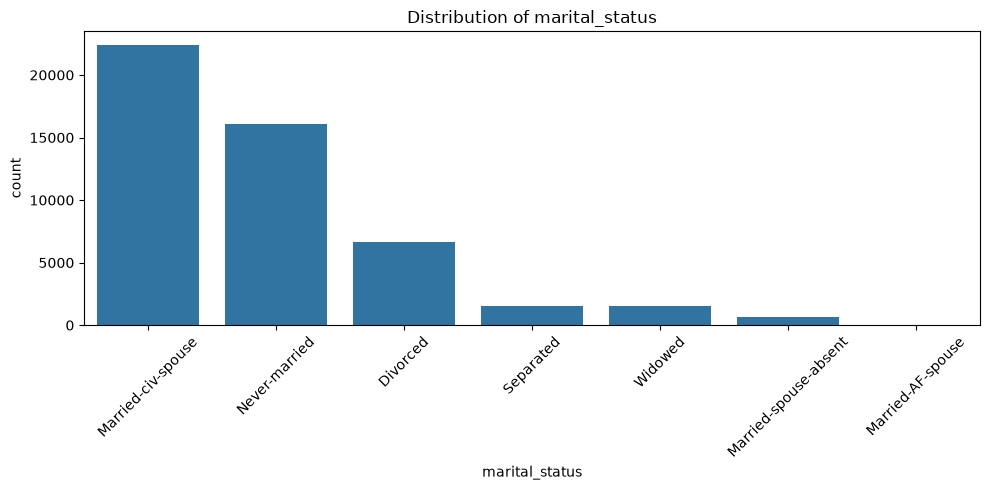

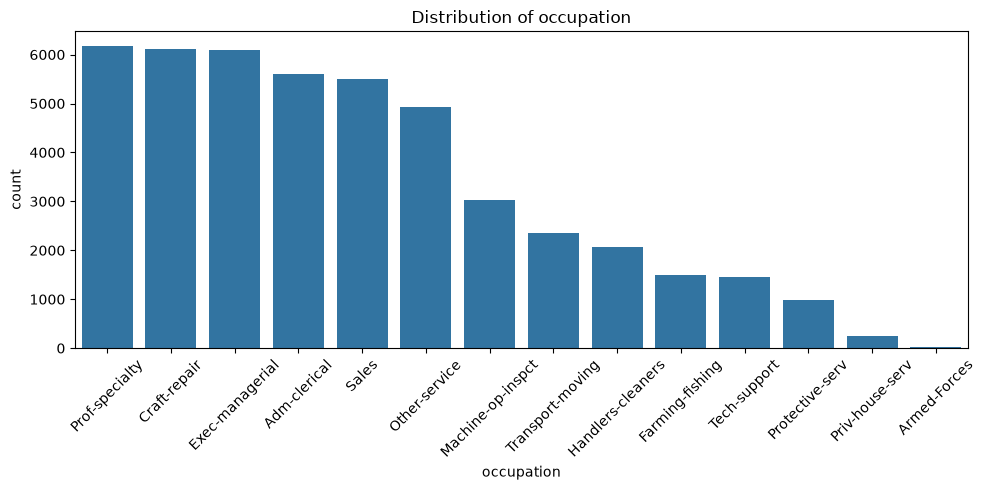

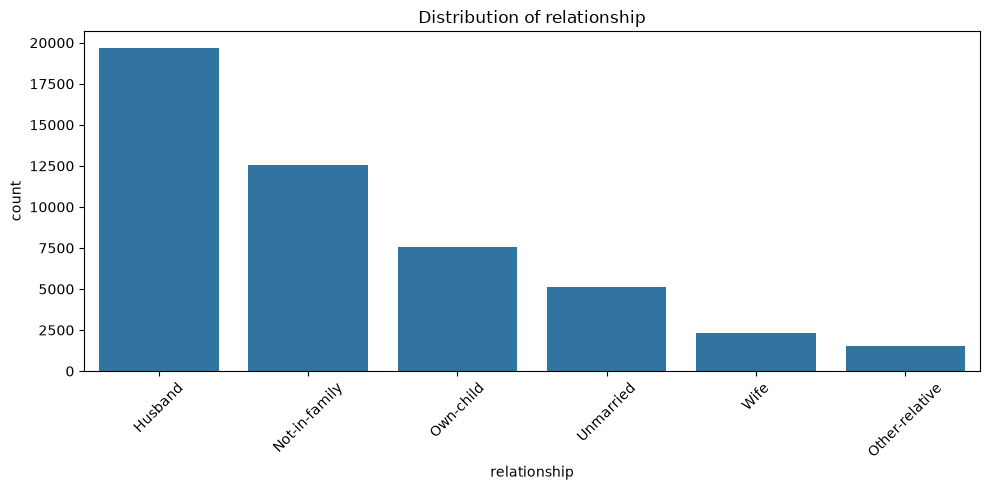

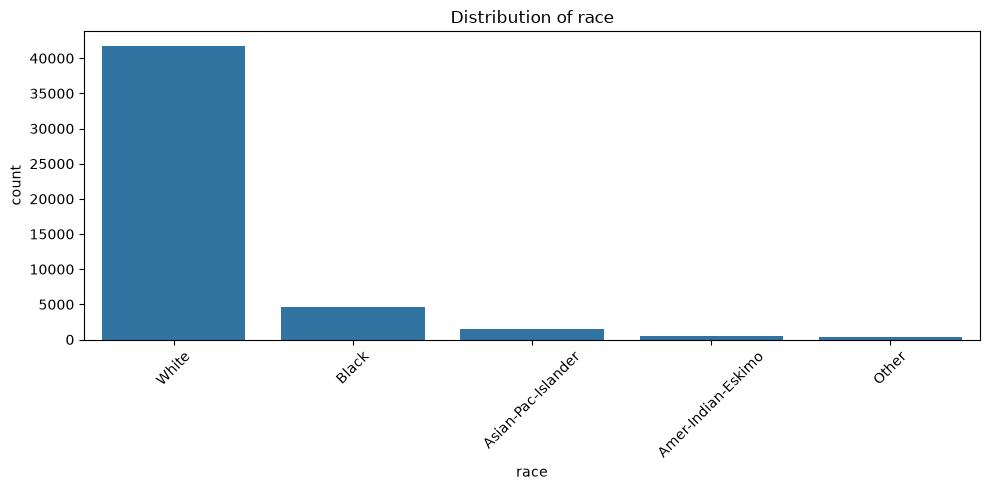

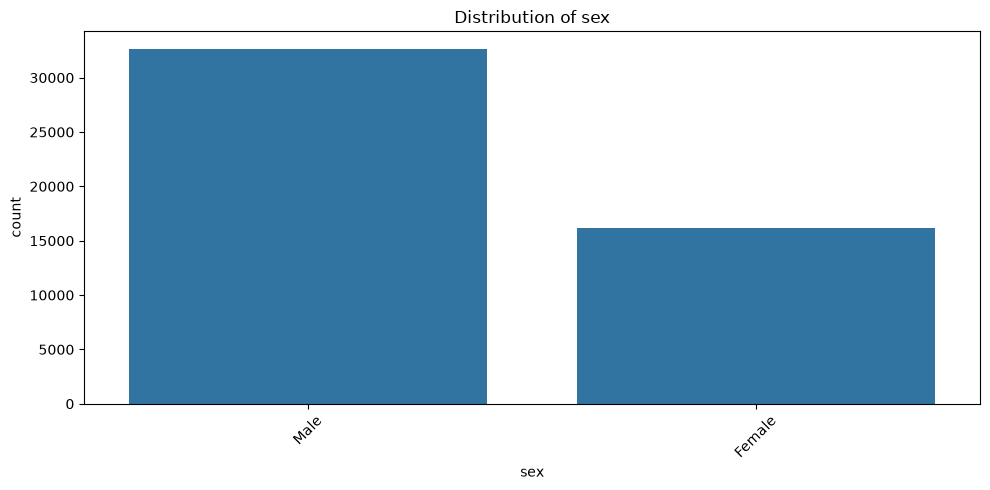

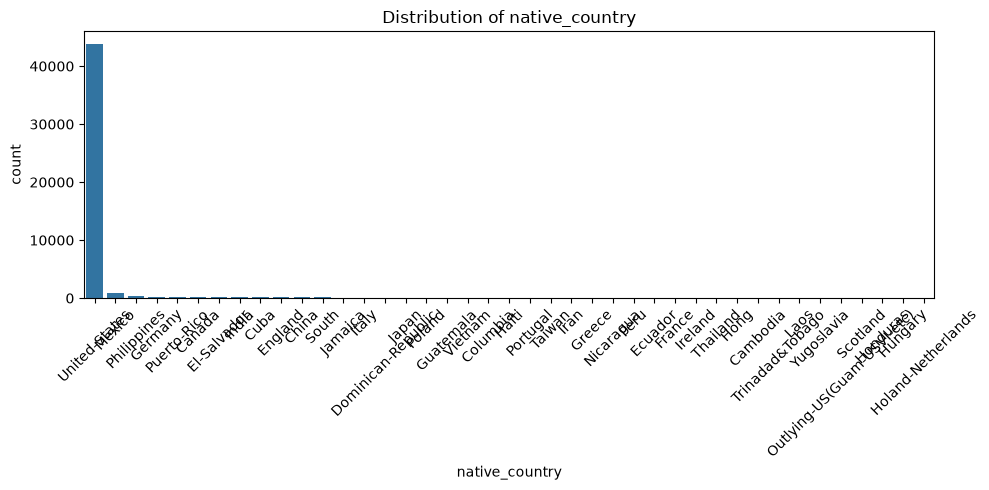

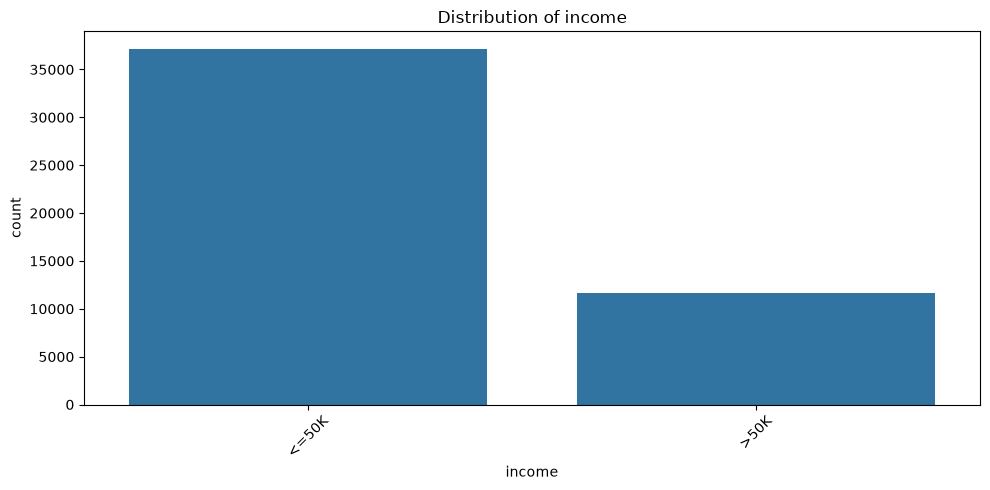

In [56]:
categorical_columns = df.select_dtypes(include=['object',"string"]).columns

for col in categorical_columns:
    plt.figure(figsize=(10,5))
    sns.countplot(data=eda, x=col, order=eda[col].value_counts().index)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

By the analisys of categorial columns several predominant categories emerged:
- native country: 
- sex : male predominant
- race : white predominant
- workclass : private predominant